# Equity Factor Analysis

## 1. Imports and Setup

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
import statsmodels.api as sm
from pandas_datareader import data as web

## 2. Data Collection and Cleaning

In [35]:
# S&P 500, Apple, Microsoft, Nvidia, JPMorgan Chase, Exxon Mobil, Johnson & Johnson
tickers = ["SPY", "AAPL", "MSFT", "NVDA", "JPM", "XOM", "JNJ"]

data = yf.download(
    tickers,
    start="2020-01-01",
    end="2026-10-01",
    auto_adjust=True, # Adjusts data for splits & dividends
    threads=False # Download data sequentially
)

data.head() # Show first few rows of downloaded data

[*********************100%***********************]  7 of 7 completed


Price           Close                                                \
Ticker           AAPL         JNJ         JPM        MSFT      NVDA   
Date                                                                  
2020-01-02  72.271538  121.338516  117.313934  151.544281  5.957138   
2020-01-03  71.568924  119.933754  115.765831  149.657242  5.861788   
2020-01-06  72.139175  119.784058  115.673775  150.044083  5.886370   
2020-01-07  71.799934  120.515541  113.707253  148.675995  5.957634   
2020-01-08  72.954918  120.498970  114.594254  151.044189  5.968808   

Price                                   High                          ...  \
Ticker             SPY        XOM       AAPL         JNJ         JPM  ...   
Date                                                                  ...   
2020-01-02  295.391785  52.606396  72.331694  121.380082  117.322257  ...   
2020-01-03  293.154968  52.183475  72.326889  120.839821  116.510601  ...   
2020-01-06  294.273346  52.584141  72.177676  119.867176  115.707255  ...   
2020-01-07  293.445953  52.153793  72.403897  120.906233  115.364155  ...   
2020-01-08  295.009857  51.367294  73.255698  121.346843  115.129818  ...   

Price           Open                            Volume                     \
Ticker          NVDA         SPY        XOM       AAPL      JNJ       JPM   
Date                                                                        
2020-01-02  5.928334  294.182479  52.116686  135480400  5777000  10803700   
2020-01-03  5.837702  292.018392  52.932872  146322800  5752400  10386800   
2020-01-06  5.768672  291.409151  52.176049  118387200  7731300  10259000   
2020-01-07  5.914677  293.709619  52.309609  108872000  7382900  10531300   
2020-01-08  5.953413  293.636864  52.020235  132079200  6605800   9695300   

Price                                                
Ticker          MSFT       NVDA       SPY       XOM  
Date                                                 
2020-01-02  22622100  237536000  59151200  12456400  
2020-01-03  21116200  205384000  77709700  17386900  
2020-01-06  20813700  262636000  55653900  20081900  
2020-01-07  21634100  314856000  40496400  17387700  
2020-01-08  27746500  277108000  68296000  15137700  

[5 rows x 35 columns]

In [36]:
prices = data["Close"]  # Keep only the closing prices

prices.shape # (of training days, # of stocks)
prices.index.min(), prices.index.max() # Check date range
prices.isna().sum() # Check for missing values

prices.head()

Ticker,AAPL,JNJ,JPM,MSFT,NVDA,SPY,XOM
Date,,,,,,,
2020-01-02,72.271538,121.338516,117.313934,151.544281,5.957138,295.391785,52.606396
2020-01-03,71.568924,119.933754,115.765831,149.657242,5.861788,293.154968,52.183475
2020-01-06,72.139175,119.784058,115.673775,150.044083,5.886370,294.273346,52.584141
2020-01-07,71.799934,120.515541,113.707253,148.675995,5.957634,293.445953,52.153793
2020-01-08,72.954918,120.498970,114.594254,151.044189,5.968808,295.009857,51.367294


In [37]:
returns = prices.pct_change().dropna() # Calculate daily % changes, remove rows with NaN
returns.head()

Ticker,AAPL,JNJ,JPM,MSFT,NVDA,SPY,XOM
Date,,,,,,,
2020-01-03,-0.009722,-0.011577,-0.013196,-0.012452,-0.016006,-0.007572,-0.008039
2020-01-06,0.007968,-0.001248,-0.000795,0.002585,0.004194,0.003815,0.007678
2020-01-07,-0.004703,0.006107,-0.017001,-0.009118,0.012107,-0.002812,-0.008184
2020-01-08,0.016086,-0.000138,0.007801,0.015929,0.001876,0.005329,-0.015080
2020-01-09,0.021241,0.002966,0.003651,0.012493,0.010982,0.006781,0.007655


In [38]:
prices.to_csv("../data/prices.csv") # Save closing prices
returns.to_csv("../data/daily_returns.csv") # Save daily returns

## 3. Exploratory Data Analysis

In [39]:
returns.describe()

Ticker,AAPL,JNJ,JPM,MSFT,NVDA,SPY,XOM
count,1694.000000,1694.000000,1694.000000,1694.000000,1694.000000,1694.000000,1694.000000
mean,0.001096,0.000538,0.000794,0.000902,0.002682,0.000640,0.000875
std,0.019706,0.012413,0.019234,0.019126,0.032592,0.012630,0.020376
min,-0.128647,-0.075916,-0.149649,-0.147391,-0.184521,-0.109424,-0.122248
25%,-0.008141,-0.005567,-0.007958,-0.008465,-0.015389,-0.004595,-0.010135
50%,0.001149,0.000397,0.001032,0.000908,0.002893,0.000900,0.000734
75%,0.011198,0.006677,0.009792,0.010518,0.021132,0.006702,0.011746
max,0.153288,0.079977,0.180125,0.155067,0.243696,0.105019,0.126868


In [40]:
correlation_matrix = returns.corr() # Show how similar the stocks move
correlation_matrix

Ticker,AAPL,JNJ,JPM,MSFT,NVDA,SPY,XOM
Ticker,,,,,,,
AAPL,1.000000,0.302684,0.404470,0.638511,0.542597,0.753422,0.256569
JNJ,0.302684,1.000000,0.336073,0.229846,0.060216,0.399186,0.266422
JPM,0.404470,0.336073,1.000000,0.388056,0.329501,0.694995,0.499424
MSFT,0.638511,0.229846,0.388056,1.000000,0.622242,0.751528,0.190011
NVDA,0.542597,0.060216,0.329501,0.622242,1.000000,0.698596,0.149185
SPY,0.753422,0.399186,0.694995,0.751528,0.698596,1.000000,0.447980
XOM,0.256569,0.266422,0.499424,0.190011,0.149185,0.447980,1.000000


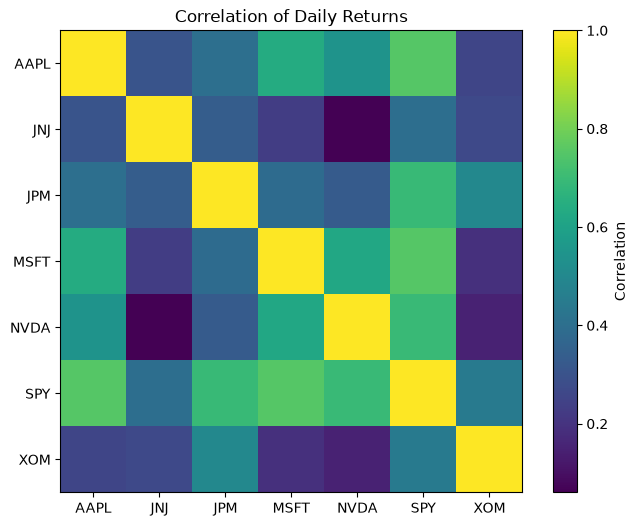

In [41]:
fig, ax = plt.subplots(figsize=(8, 6))

image = ax.imshow(correlation_matrix)

ax.set_xticks(range(len(correlation_matrix.columns)))
ax.set_yticks(range(len(correlation_matrix.columns)))

ax.set_xticklabels(correlation_matrix.columns)
ax.set_yticklabels(correlation_matrix.columns)

plt.colorbar(image, label="Correlation")
plt.title("Correlation of Daily Returns")
plt.show()

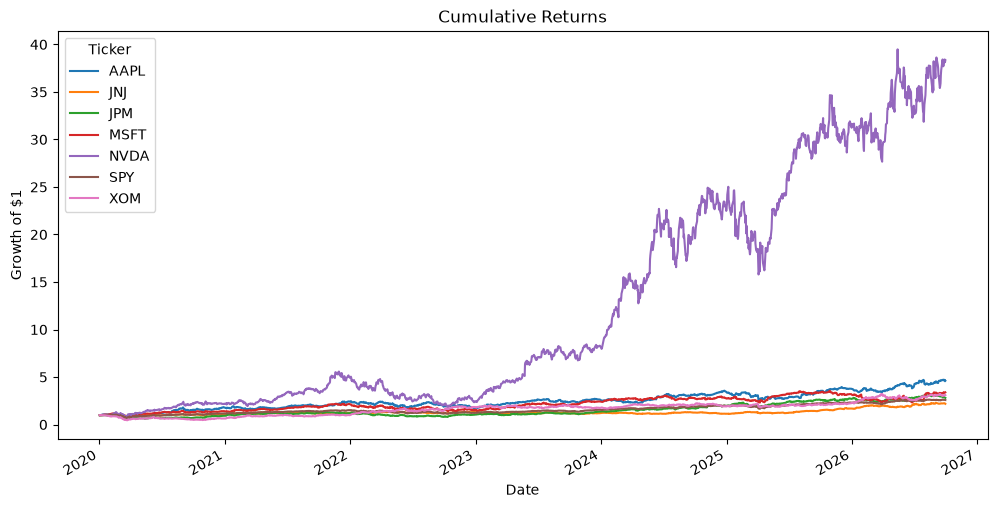

In [42]:
# Show how the stocks move over time
cumulative_returns = (1 + returns).cumprod()

cumulative_returns.plot(
    figsize=(12, 6),
    title="Cumulative Returns"
)

plt.ylabel("Growth of $1")
plt.xlabel("Date")
plt.show()

In [43]:
daily_volatility = returns.std() # Calculate standard deviation of returns

annualized_volatility = returns.std() * np.sqrt(252) # Annualize the volatility

annualized_volatility.sort_values(ascending=False) # Sort from most to least volatile

Ticker
NVDA    0.517387
XOM     0.323451
AAPL    0.312831
JPM     0.305330
MSFT    0.303611
SPY     0.200496
JNJ     0.197049
dtype: float64

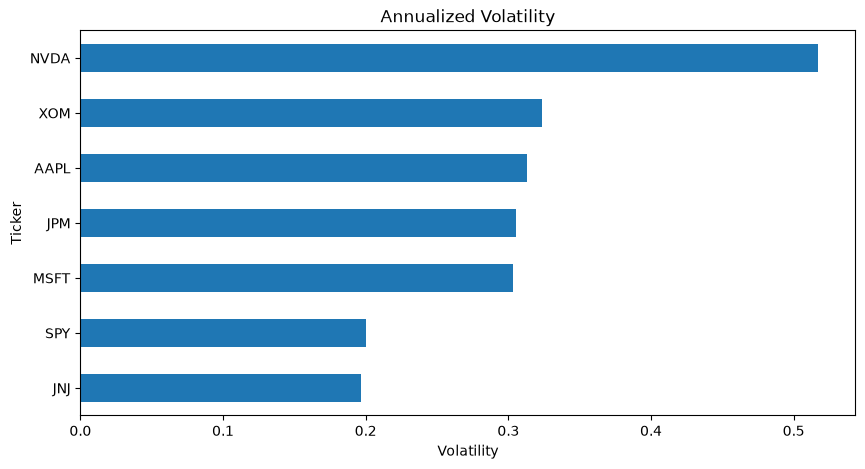

In [44]:
annualized_volatility.sort_values().plot(
    kind="barh",
    figsize=(10, 5),
    title="Annualized Volatility"
)

plt.xlabel("Volatility")
plt.ylabel("Ticker")
plt.show()

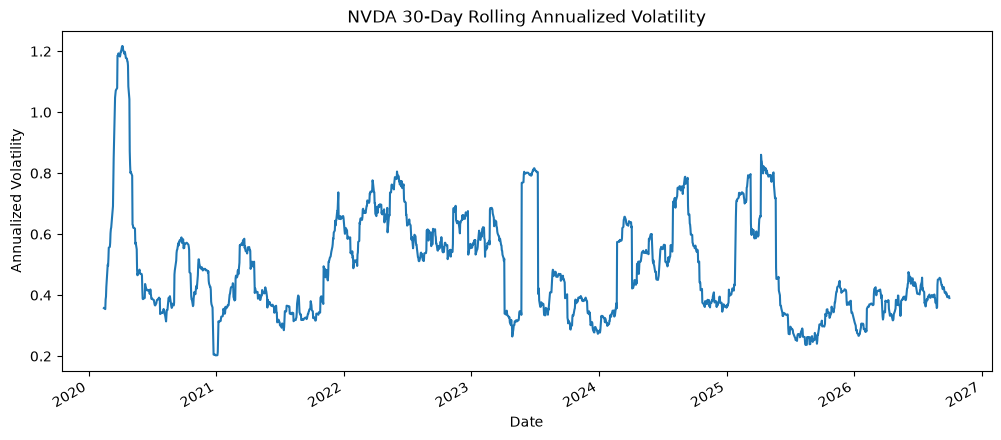

In [45]:
rolling_volatility = returns.rolling(window=30).std() * np.sqrt(252) # See how risk changes over time

rolling_volatility["NVDA"].plot(
    figsize=(12, 5),
    title="NVDA 30-Day Rolling Annualized Volatility"
)

plt.ylabel("Annualized Volatility")
plt.xlabel("Date")
plt.show()

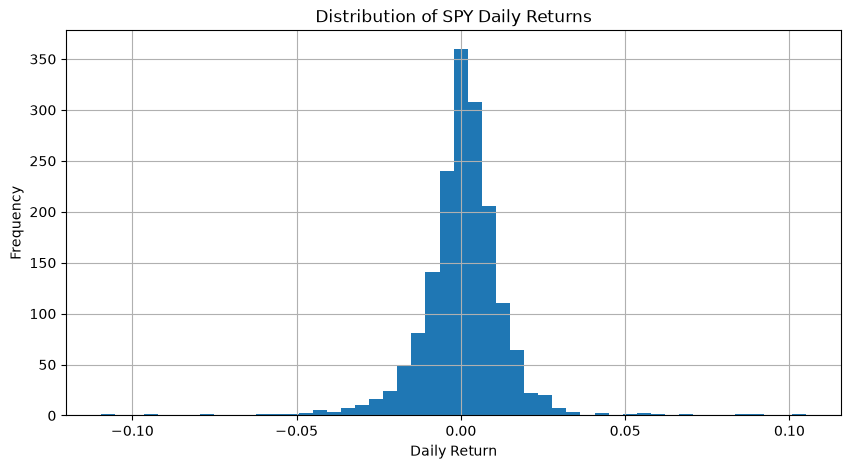

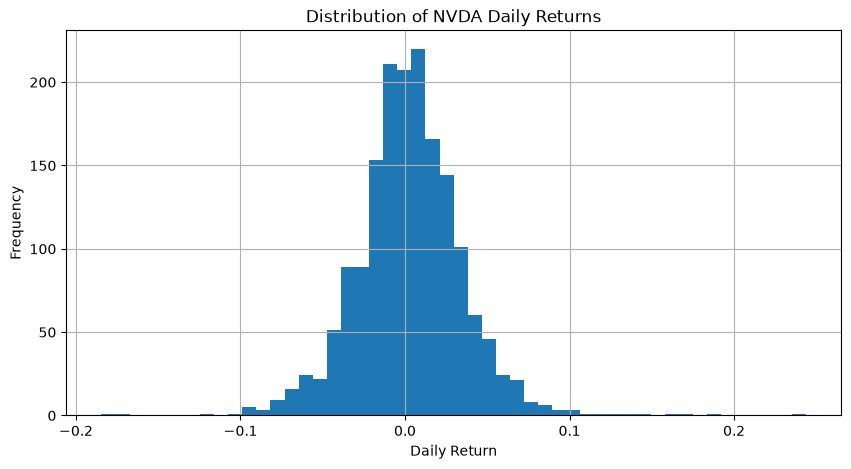

In [46]:
returns["SPY"].hist(
    bins=50,
    figsize=(10, 5)
)

plt.title("Distribution of SPY Daily Returns")
plt.xlabel("Daily Return")
plt.ylabel("Frequency")
plt.show()

returns["NVDA"].hist(
    bins=50,
    figsize=(10, 5)
)

plt.title("Distribution of NVDA Daily Returns")
plt.xlabel("Daily Return")
plt.ylabel("Frequency")
plt.show()

## 4. Single-Factor Market Model

In [47]:
y = returns["AAPL"]  # Apple daily returns
X = returns["SPY"]   # Market daily returns

X = sm.add_constant(X)

model = sm.OLS(y, X) # OLS = Ordinary Least Squares
results = model.fit()

results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   AAPL   R-squared:                       0.568
Model:                            OLS   Adj. R-squared:                  0.567
Method:                 Least Squares   F-statistic:                     2221.
Date:                Mon, 12 Oct 2026   Prob (F-statistic):          2.15e-310
Time:                        22:13:50   Log-Likelihood:                 4959.0
No. Observations:                1694   AIC:                            -9914.
Df Residuals:                    1692   BIC:                            -9903.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0003      0.000      1.089      0.276      -0.000       0.001
SPY            1.1756      0.025     47.132      0.000       1.127       1.224
==============================================================================
Omnibus:                      201.722   Durbin-Watson:                   1.831
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1645.141
Skew:                           0.226   Prob(JB):                         0.00
Kurtosis:                       7.807   Cond. No.                         79.2
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

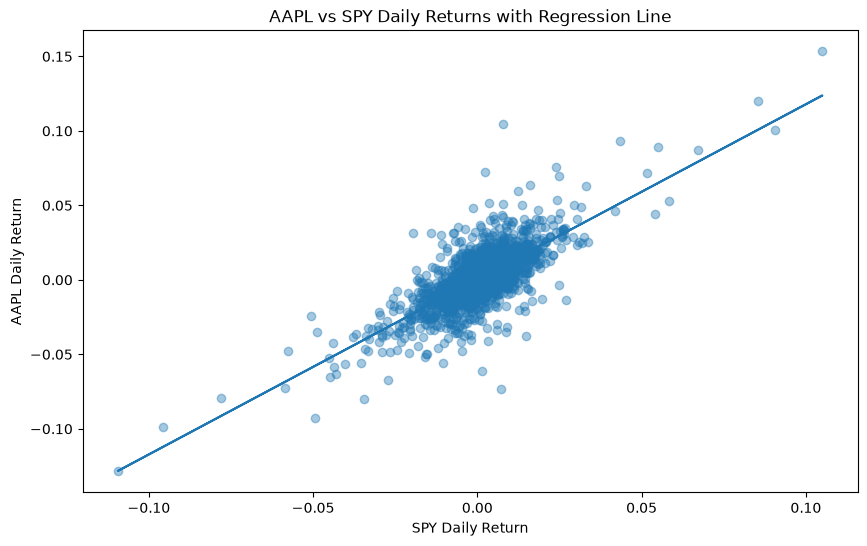

In [48]:
# Add regression line to the scatter plot
plt.figure(figsize=(10, 6))

plt.scatter(
    returns["SPY"],
    returns["AAPL"],
    alpha=0.4
)

x_values = returns["SPY"]

predicted_aapl = (
    results.params["const"]
    + results.params["SPY"] * x_values
)

plt.plot(
    x_values,
    predicted_aapl
)

plt.xlabel("SPY Daily Return")
plt.ylabel("AAPL Daily Return")
plt.title("AAPL vs SPY Daily Returns with Regression Line")

plt.show()

In [49]:
stocks = ["AAPL", "MSFT", "NVDA", "JPM", "XOM", "JNJ"]
# Run regression for each stock against SPY
results_table = []

for stock in stocks:
    y = returns[stock]
    X = sm.add_constant(returns["SPY"])

    model = sm.OLS(y, X).fit()

    results_table.append({
        "Stock": stock,
        "Alpha": model.params["const"],
        "Beta": model.params["SPY"],
        "R_squared": model.rsquared
    })

# Create a DataFrame to display the results
comparison = pd.DataFrame(results_table)

comparison

,Stock,Alpha,Beta,R_squared
0,AAPL,0.000344,1.175554,0.567644
1,MSFT,0.000174,1.138040,0.564794
2,NVDA,0.001528,1.802753,0.488037
3,JPM,0.000116,1.058392,0.483019
4,XOM,0.000412,0.722708,0.200686
5,JNJ,0.000286,0.392323,0.159350


In [50]:
# Show which stocks were most sensitive to market movements (highest beta)
comparison.sort_values("Beta", ascending=False)

,Stock,Alpha,Beta,R_squared
2,NVDA,0.001528,1.802753,0.488037
0,AAPL,0.000344,1.175554,0.567644
1,MSFT,0.000174,1.138040,0.564794
3,JPM,0.000116,1.058392,0.483019
4,XOM,0.000412,0.722708,0.200686
5,JNJ,0.000286,0.392323,0.159350


## 5. Rolling Beta Analysis

In [51]:
# Test whether beta is stable over time
window = 126  # about 6 months of trading days

rolling_cov = returns["NVDA"].rolling(window).cov(returns["SPY"])
rolling_var = returns["SPY"].rolling(window).var()

rolling_beta_nvda = rolling_cov / rolling_var

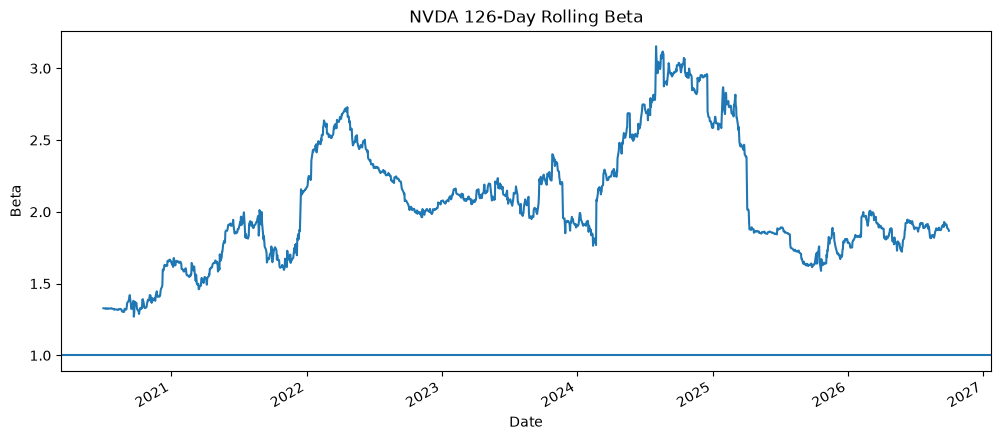

In [52]:
rolling_beta_nvda.plot(
    figsize=(12, 5),
    title="NVDA 126-Day Rolling Beta"
)

plt.axhline(1)
plt.ylabel("Beta")
plt.xlabel("Date")
plt.show()

In [53]:
# Calculate rolling betas for all stocks
rolling_betas = pd.DataFrame(index=returns.index)

for stock in stocks:
    rolling_cov = returns[stock].rolling(window).cov(returns["SPY"])
    rolling_var = returns["SPY"].rolling(window).var()

    rolling_betas[stock] = rolling_cov / rolling_var

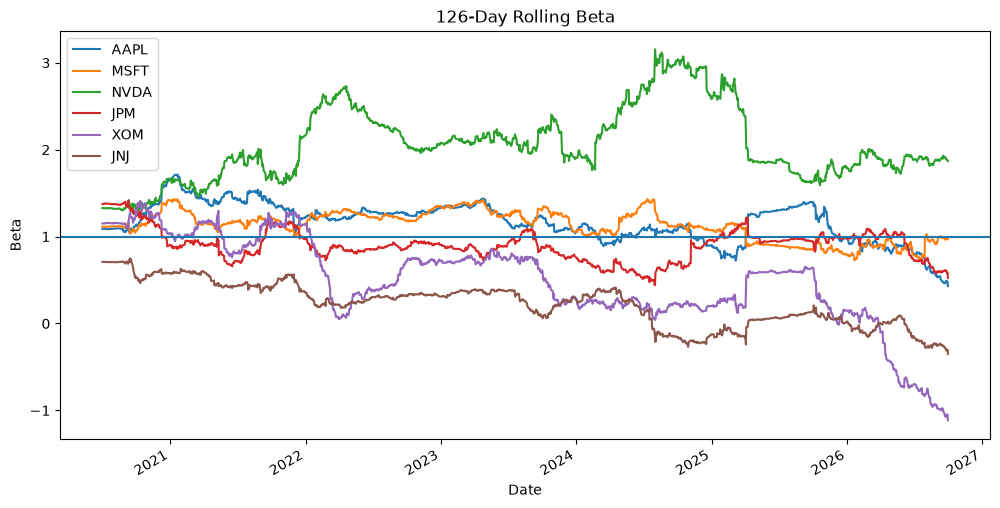

In [54]:
rolling_betas.plot(
    figsize=(12, 6),
    title="126-Day Rolling Beta"
)

plt.axhline(1)
plt.ylabel("Beta")
plt.xlabel("Date")
plt.show()

## 6. Out-of-Sample Testing

In [55]:
# Split the data into training and testing sets
train = returns.loc["2020-01-01":"2024-12-31"]
test = returns.loc["2025-01-01":"2026-09-30"]

In [56]:
X_train = sm.add_constant(train["SPY"])
y_train = train["AAPL"]

train_model = sm.OLS(y_train, X_train).fit()

In [57]:
# Compare the model's predictions to the actual AAPL returns in the test set
X_test = sm.add_constant(test["SPY"])

predicted_aapl = train_model.predict(X_test)
actual_aapl = test["AAPL"]

In [58]:
# Calculate Mean Squared Error (MSE) for the predictions
mse = np.mean((actual_aapl - predicted_aapl) ** 2)

train_mean = train["AAPL"].mean()

ss_res = np.sum((actual_aapl - predicted_aapl) ** 2)
ss_tot = np.sum((actual_aapl - train_mean) ** 2)

out_of_sample_r2 = 1 - (ss_res / ss_tot)

print("MSE:", mse)
print("Out-of-sample R-squared:", out_of_sample_r2)

MSE: 0.0002216101128152103
Out-of-sample R-squared: 0.38436663860300724


In [59]:
oos_results = []

for stock in stocks:
    # Training data
    X_train = sm.add_constant(train["SPY"])
    y_train = train[stock]

    model = sm.OLS(y_train, X_train).fit()

    # Test data
    X_test = sm.add_constant(test["SPY"])
    actual = test[stock]
    predicted = model.predict(X_test)

    # Mean squared error
    mse = np.mean((actual - predicted) ** 2)

    # Out-of-sample R-squared
    train_mean = train[stock].mean()

    ss_res = np.sum((actual - predicted) ** 2)
    ss_tot = np.sum((actual - train_mean) ** 2)

    oos_r2 = 1 - (ss_res / ss_tot)

    oos_results.append({
        "Stock": stock,
        "Train_Beta": model.params["SPY"],
        "Train_R2": model.rsquared,
        "Test_MSE": mse,
        "Out_of_Sample_R2": oos_r2
    })

oos_comparison = pd.DataFrame(oos_results)
oos_comparison

,Stock,Train_Beta,Train_R2,Test_MSE,Out_of_Sample_R2
0,AAPL,1.192820,0.625093,0.000222,0.384367
1,MSFT,1.189703,0.670940,0.000269,0.244105
2,NVDA,1.785895,0.484398,0.000401,0.502317
3,JPM,1.094130,0.498871,0.000137,0.395120
4,XOM,0.846758,0.267451,0.000308,-0.181467
5,JNJ,0.485627,0.269102,0.000186,-0.183852


## 7. Fama-French Three-Factor Model

In [60]:
ff_data = web.DataReader(
    "F-F_Research_Data_Factors_daily",
    "famafrench",
    start="2020-01-01"
)[0]

ff_data = ff_data / 100

# Standardize the date indexes so the datasets can be matched

returns.index = pd.to_datetime(returns.index).normalize()

ff_data.index = ff_data.index.to_timestamp()
ff_data.index = pd.to_datetime(ff_data.index).normalize()

ff_data.head()

,Mkt-RF,SMB,HML,RF
Date,,,,
2020-01-02,0.0086,-0.0088,-0.0034,0.0001
2020-01-03,-0.0067,0.0038,0.0001,0.0001
2020-01-06,0.0036,-0.0007,-0.0055,0.0001
2020-01-07,-0.0019,-0.0001,-0.0026,0.0001
2020-01-08,0.0047,-0.0007,-0.0064,0.0001


In [61]:
aapl_ff = pd.concat(
    [
        returns["AAPL"],
        ff_data[["Mkt-RF", "SMB", "HML", "RF"]]
    ],
    axis=1,
    join="inner"
)

aapl_ff["AAPL_excess"] = aapl_ff["AAPL"] - aapl_ff["RF"]

aapl_ff.head()

,AAPL,Mkt-RF,SMB,HML,RF,AAPL_excess
Date,,,,,,
2020-01-03,-0.009722,-0.0067,0.0038,0.0001,0.0001,-0.009822
2020-01-06,0.007968,0.0036,-0.0007,-0.0055,0.0001,0.007868
2020-01-07,-0.004703,-0.0019,-0.0001,-0.0026,0.0001,-0.004803
2020-01-08,0.016086,0.0047,-0.0007,-0.0064,0.0001,0.015986
2020-01-09,0.021241,0.0065,-0.0063,-0.0048,0.0001,0.021141


In [62]:
y = aapl_ff["AAPL_excess"]

X = aapl_ff[["Mkt-RF", "SMB", "HML"]]
X = sm.add_constant(X)

ff_model = sm.OLS(y, X).fit()

ff_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            AAPL_excess   R-squared:                       0.603
Model:                            OLS   Adj. R-squared:                  0.602
Method:                 Least Squares   F-statistic:                     844.4
Date:                Mon, 12 Oct 2026   Prob (F-statistic):               0.00
Time:                        22:13:51   Log-Likelihood:                 4963.8
No. Observations:                1673   AIC:                            -9920.
Df Residuals:                    1669   BIC:                            -9898.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0003      0.000      1.147      0.252      -0.000       0.001
Mkt-RF         1.1489      0.024     47.495      0.000       1.101       1.196
SMB           -0.3124      0.043     -7.338      0.000      -0.396      -0.229
HML           -0.3036      0.029    -10.499      0.000      -0.360      -0.247
==============================================================================
Omnibus:                      203.544   Durbin-Watson:                   1.843
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1824.220
Skew:                           0.185   Prob(JB):                         0.00
Kurtosis:                       8.102   Cond. No.                         142.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [63]:
ff_results = []

for stock in stocks:
    stock_ff = pd.concat(
        [
            returns[stock],
            ff_data[["Mkt-RF", "SMB", "HML", "RF"]]
        ],
        axis=1,
        join="inner"
    )

    stock_ff["Excess_Return"] = stock_ff[stock] - stock_ff["RF"]

    y = stock_ff["Excess_Return"]

    X = stock_ff[["Mkt-RF", "SMB", "HML"]]
    X = sm.add_constant(X)

    model = sm.OLS(y, X).fit()

    ff_results.append({
        "Stock": stock,
        "Alpha": model.params["const"],
        "Market_Beta": model.params["Mkt-RF"],
        "SMB": model.params["SMB"],
        "HML": model.params["HML"],
        "R_squared": model.rsquared
    })
    
ff_comparison = pd.DataFrame(ff_results)

ff_comparison

,Stock,Alpha,Market_Beta,SMB,HML,R_squared
0,AAPL,0.000350,1.148936,-0.312447,-0.303617,0.602824
1,MSFT,0.000200,1.116940,-0.422898,-0.468951,0.656771
2,NVDA,0.001723,1.706603,-0.211738,-1.005306,0.606408
3,JPM,0.000057,1.116012,-0.152357,0.858841,0.703057
4,XOM,0.000261,0.788834,-0.047085,0.980119,0.457202
5,JNJ,0.000168,0.426723,-0.340520,0.190490,0.207094


In [64]:
model_comparison = comparison[
    ["Stock", "Beta", "R_squared"]
].merge(
    ff_comparison[
        ["Stock", "Market_Beta", "SMB", "HML", "R_squared"]
    ],
    on="Stock",
    suffixes=("_Single_Factor", "_Fama_French")
)

model_comparison["R2_Improvement"] = (
    model_comparison["R_squared_Fama_French"]
    - model_comparison["R_squared_Single_Factor"]
)

model_comparison

,Stock,Beta,R_squared_Single_Factor,Market_Beta,SMB,HML,R_squared_Fama_French,R2_Improvement
0,AAPL,1.175554,0.567644,1.148936,-0.312447,-0.303617,0.602824,0.035180
1,MSFT,1.138040,0.564794,1.116940,-0.422898,-0.468951,0.656771,0.091978
2,NVDA,1.802753,0.488037,1.706603,-0.211738,-1.005306,0.606408,0.118372
3,JPM,1.058392,0.483019,1.116012,-0.152357,0.858841,0.703057,0.220038
4,XOM,0.722708,0.200686,0.788834,-0.047085,0.980119,0.457202,0.256516
5,JNJ,0.392323,0.159350,0.426723,-0.340520,0.190490,0.207094,0.047744


## 8. Model Comparison

In [65]:
fair_comparison = []

for stock in stocks:
    stock_ff = pd.concat(
        [
            returns[stock],
            ff_data[["Mkt-RF", "SMB", "HML", "RF"]]
        ],
        axis=1,
        join="inner"
    ).dropna()

    # Stock return above the risk-free rate
    stock_ff["Excess_Return"] = stock_ff[stock] - stock_ff["RF"]

    y = stock_ff["Excess_Return"]

    # Single-factor model
    X_single = sm.add_constant(stock_ff[["Mkt-RF"]])
    single_model = sm.OLS(y, X_single).fit()

    # Fama-French 3-factor model
    X_ff3 = sm.add_constant(stock_ff[["Mkt-RF", "SMB", "HML"]])
    ff3_model = sm.OLS(y, X_ff3).fit()

    fair_comparison.append({
        "Stock": stock,
        "Single_Factor_R2": single_model.rsquared,
        "Fama_French_R2": ff3_model.rsquared,
        "R2_Improvement": ff3_model.rsquared - single_model.rsquared
    })

fair_comparison = pd.DataFrame(fair_comparison)

fair_comparison

,Stock,Single_Factor_R2,Fama_French_R2,R2_Improvement
0,AAPL,0.562250,0.602824,0.040574
1,MSFT,0.561946,0.656771,0.094825
2,NVDA,0.498117,0.606408,0.108291
3,JPM,0.481621,0.703057,0.221436
4,XOM,0.201404,0.457202,0.255798
5,JNJ,0.145072,0.207094,0.062022


In [66]:
adjusted_comparison = []

for stock in stocks:
    stock_ff = pd.concat(
        [
            returns[stock],
            ff_data[["Mkt-RF", "SMB", "HML", "RF"]]
        ],
        axis=1,
        join="inner"
    ).dropna()

    stock_ff["Excess_Return"] = stock_ff[stock] - stock_ff["RF"]
    y = stock_ff["Excess_Return"]

    # Single-factor model
    X_single = sm.add_constant(stock_ff[["Mkt-RF"]])
    single_model = sm.OLS(y, X_single).fit()

    # Three-factor model
    X_ff3 = sm.add_constant(stock_ff[["Mkt-RF", "SMB", "HML"]])
    ff3_model = sm.OLS(y, X_ff3).fit()

    adjusted_comparison.append({
        "Stock": stock,
        "Single_Factor_Adj_R2": single_model.rsquared_adj,
        "Fama_French_Adj_R2": ff3_model.rsquared_adj,
        "Adj_R2_Improvement":
            ff3_model.rsquared_adj - single_model.rsquared_adj
    })

adjusted_comparison = pd.DataFrame(adjusted_comparison)

adjusted_comparison

,Stock,Single_Factor_Adj_R2,Fama_French_Adj_R2,Adj_R2_Improvement
0,AAPL,0.561988,0.602110,0.040122
1,MSFT,0.561684,0.656154,0.094471
2,NVDA,0.497817,0.605701,0.107884
3,JPM,0.481311,0.702523,0.221212
4,XOM,0.200926,0.456226,0.255300
5,JNJ,0.144561,0.205669,0.061108


## 9. Key Findings

### 1. Market sensitivity differs substantially across stocks

The single-factor regressions showed large differences in beta across the six equities.

- NVDA had the highest full-sample beta at approximately 1.80, indicating substantially greater sensitivity to broad market movements.
- AAPL and MSFT had betas slightly above 1.
- JPM had a beta close to 1.
- XOM and JNJ had lower market betas of approximately 0.72 and 0.39.

This suggests that exposure to broad market movements varies considerably across companies and sectors.

### 2. Beta is not constant over time

NVDA's 126-day rolling beta varied substantially over the sample period, ranging from roughly 1.3 to above 3.0.

This shows that a single full-sample beta can hide significant changes in market sensitivity over time.

### 3. The single-factor model does not generalize equally well across stocks

Using 2020–2024 data for training and 2025–2026 data for testing:

- NVDA achieved an out-of-sample R² of approximately 0.50.
- JPM achieved approximately 0.40.
- AAPL achieved approximately 0.38.
- MSFT achieved approximately 0.24.
- XOM and JNJ produced negative out-of-sample R² values.

This suggests that broad market exposure alone is useful for explaining some stocks but is insufficient for others.

### 4. The Fama-French three-factor model improved explanatory power

Adding the SMB and HML factors increased adjusted R² for all six stocks.

The largest improvements occurred for:

- XOM: approximately +0.26
- JPM: approximately +0.22
- NVDA: approximately +0.11
- MSFT: approximately +0.09

The improvements were smaller for AAPL and JNJ.

Overall, the results suggest that additional systematic factors can explain meaningful variation that is not captured by market exposure alone.

## Main Takeaway

Simple factor models can provide useful and interpretable measures of equity risk, but their usefulness varies across securities and over time.

The analysis highlights the importance of testing model stability, evaluating performance on unseen data, and considering additional factors rather than relying on a single historical beta.

## 10. Assumptions and Limitations

### Model assumptions

The regression models used in this project rely on several simplifying assumptions:

- The relationship between stock returns and factor returns is approximately linear.
- Historical relationships are informative about future relationships.
- The model coefficients are reasonably stable over the period being analyzed.
- The residual errors are not systematically related to the explanatory variables.
- The data does not contain look-ahead bias.

### Limitations

- The analysis uses a small sample of six large U.S. equities.
- SPY is only a proxy for the broader market.
- Historical relationships may change over time, as shown by the rolling beta analysis.
- The single-factor model omits other sources of systematic risk.
- The Fama-French three-factor model is still simplified and does not include factors such as momentum or profitability.
- The models explain relationships in returns but do not establish causation.
- The project does not account for transaction costs, portfolio construction, or trading implementation.
- Strong in-sample fit does not guarantee strong future performance.

## 11. Future Work

Possible extensions include:

- Adding momentum and profitability factors
- Testing a larger universe of equities
- Comparing sector-specific models
- Testing factor stability over different market regimes
- Building and evaluating simple factor-based portfolios
- Comparing traditional factor models with machine learning approaches